# Тема 2. Моделирование связи частотного и классического определения вероятности
---
### Смоделируйте вычисление геометрической вероятности (на примере из лекции про метание дротиков в игровой круг, площадь которого в два раза меньше площади стены). Показать теоретический расчет и графическую иллюстрацию для рассматриваемого примера.

В настольной игре карта особняка, в котором происходят все события сюжета, собирается из 4 случайно выбранных комнат. Комнаты деляться на событийные (5), ресурсные (3) и пустые (4) - всего 12 комнат. Какова вероятность, что среди выбранных комнат окажется 1 событийная и 3 ресурсные?

Классическая вероятность: 0.0101
Частота: 0.0100
0.0094


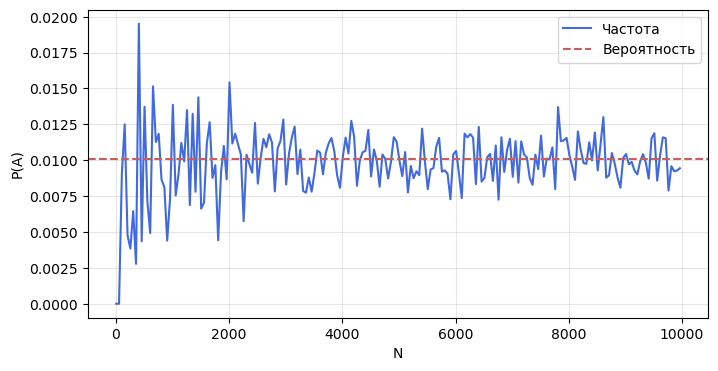

In [4]:
import numpy as np
from math import comb
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

# E — event (событийные), R — resource (ресурсные), P — empty (пустые)
mansion = ['E'] * 5 + ['R'] * 3 + ['P'] * 4

# классическая вероятность
p = comb(5, 1) * comb(3, 3) * comb(4, 0) / comb(12, 4)
print(f'Классическая вероятность: {p:.4f}')

# частотная вероятность
N_A = 0
for _ in range(1000000):
    comb_rooms = np.random.choice(mansion, size=4, replace=False)
    c = Counter(comb_rooms)
    if c['E'] == 1 and c['R'] == 3 and c['P'] == 0:
        N_A += 1

freq = N_A / 1000000
print(f'Частота: {freq:.4f}')

# сходимость частоты
N_values = np.array(range(10, 10001, 50))
P_A_values = []

for N in N_values:
    N_A = 0
    for _ in range(N):
        comb_rooms = np.random.choice(mansion, size=4, replace=False)
        c = Counter(comb_rooms)
        if c['E'] == 1 and c['R'] == 3 and c['P'] == 0:
            N_A += 1
    P_A_values.append(N_A / N)

print(round(P_A_values[-1], 4))

plt.figure(figsize=(8, 4))
plt.plot(N_values, P_A_values, color='royalblue', label='Частота', linewidth=1.5)
plt.axhline(y=p, color='indianred', linestyle='--', label='Вероятность')
plt.xlabel('N')
plt.ylabel('P(A)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()